# 3. Measurements

Two kinds of measurement act on a GBCS:

- a projective measurement of the qubits, which picks a combination of branches and leaves the mode in the state $\mathrm{Tr}_q[\Pi\,\hat\varrho]/p$;
- a Gaussian (general-dyne) measurement of a mode, homodyne or heterodyne with a finite efficiency, which reads out which branch the qubits are in and leaves the qubits in an updated state.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from gbcs import Quantum_State, Hamiltonian, Decoherence
from gbcs import Wigner_Functions

I2 = np.eye(2)
SIGMA_X = np.array([[0., 1.], [1., 0.]])

def show_wigner(ax, W, x, p, title):
    limit = np.max(np.abs(W))
    ax.imshow(W, origin='lower', extent=[x[0], x[-1], p[0], p[-1]], cmap='RdBu_r', vmin=-limit, vmax=limit)
    ax.set_xlabel('$x$')
    ax.set_title(title)

## Measuring the qubit

Take the Stern–Gerlach interferometer of tutorial 1 and measure $\sigma_x$. `Qubit_Ideal_Measurament(operator, 'Time')` sets the outcomes, their probabilities `prob_t` at every time, the projectors and the qubit state after each outcome. The probability of $+1$ is $\tfrac12(1 + e^{-\mathcal C}\cos\phi)$. It only departs from $\tfrac12$ near $\tau = 0$ and $\tau = 2\pi$, where the branches overlap. At recombination the phase is $\phi(2\pi) = 4\pi f_q f_u = 3\pi$ here, so the qubit comes back flipped: the outcome at $2\pi$ measures the unknown force.

outcomes: [-1.  1.]


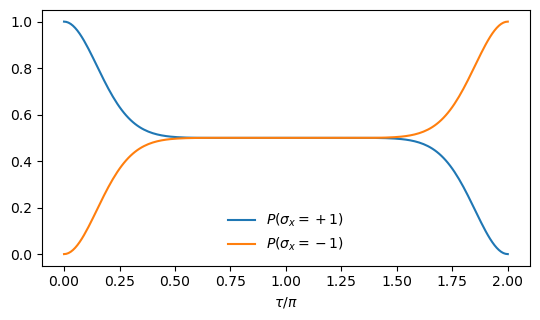

In [2]:
f_q, f_u = 1.5, 0.5
H_sg = Hamiltonian(1, 1)
H_sg.Initialize_Constant_Hamiltonians([I2], [np.array([[f_u], [0.]]), np.array([[f_q], [0.]])], np.array([0.0]))
tau = np.linspace(0, 2*np.pi, 201)
sg = Quantum_State(1, 1)
sg.Initialize_Gaussian_State(np.zeros((2, 1)), I2, np.ones((2, 2))/2)
sg.Unitary_Dynamics_Numerical(H_sg, tau)

sg.Qubit_Ideal_Measurament(SIGMA_X, 'Time')
print('outcomes:', sg.outcomes)

fig, ax = plt.subplots(figsize=(5.5, 3.3))
ax.plot(tau/np.pi, sg.prob_t[1], label=r'$P(\sigma_x = +1)$')
ax.plot(tau/np.pi, sg.prob_t[0], label=r'$P(\sigma_x = -1)$')
ax.set_xlabel(r'$\tau/\pi$')
ax.legend(frameon=False)
plt.tight_layout()

After the measurement the mode is left in one of two states. At maximum separation, $\tau = \pi$, both contain the two wavepackets, and the interference fringes between them have opposite signs for the two outcomes. `Wigner_PMS_func` returns the normalised Wigner function of the mode for each outcome.

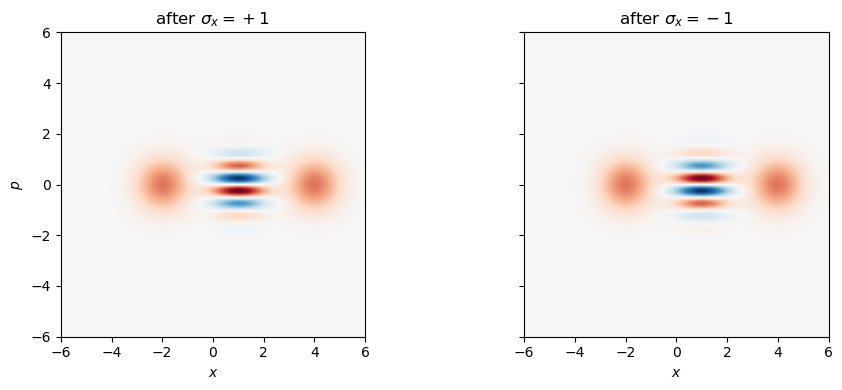

In [3]:
grid, x, p, _, _ = Wigner_Functions.Create_r_tilde_array(sg, 1.5, 0, 151)
W = Wigner_Functions.Wigner_PMS_func(sg, 100, grid)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
show_wigner(axes[0], W[1], x, p, r'after $\sigma_x = +1$')
show_wigner(axes[1], W[0], x, p, r'after $\sigma_x = -1$')
axes[0].set_ylabel('$p$')
plt.tight_layout()

## Homodyne readout of the qubit

In the dispersive readout of tutorial 2, the two pointer states are separated along $x$. A homodyne measurement of $x$ with efficiency $\eta$ therefore reads the qubit. `Mode_Measurament(['Final', 'Homodyne'], mode, angle, eta, outcomes)` measures $x\cos\theta + p\sin\theta$. It sets the outcome probabilities `Prob_Dis`, normalised over the outcomes given, and `Qubit_PMS[:, :, k] / Prob_Dis[k]`, the qubit state after outcome $k$.

The measurement noise $(1-\eta)/\eta$ adds to the width of each peak. Lower efficiency therefore makes the peaks overlap, and the qubit state after an outcome near $x = 0$ is less certain.

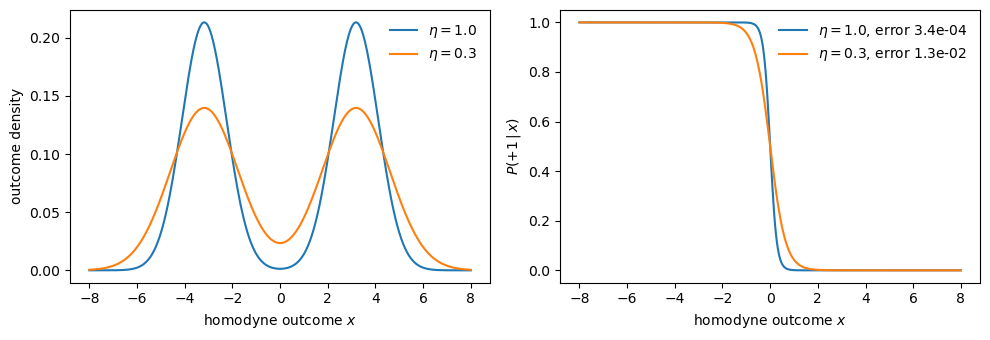

In [4]:
kappa, mu, lam, alpha_in = 1.0, 0.4, 0.3, 1.8
H_ro = Hamiltonian(1, 1)
H_ro.Initialize_Constant_Hamiltonians([lam*SIGMA_X, mu*I2], [np.zeros((2, 1)), np.zeros((2, 1))], np.array([0.0]))
d = alpha_in*np.sqrt(2*kappa)*np.array([[1.], [0.]])
ro = Quantum_State(1, 1)
ro.Initialize_Gaussian_State(np.zeros((2, 1)), I2, np.ones((2, 2))/2)
ro.Open_Dynamics_Numerical(H_ro, Decoherence(1, 1, 'Ladder', kappa*np.array([[0., 1.], [0., 0.]]), d_vec=d),
                           np.linspace(0, 20, 201), solver='linear')

m = np.linspace(-8, 8, 401)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for eta in (1.0, 0.3):
    ro.Mode_Measurament(['Final', 'Homodyne'], 0, 0.0, eta, m)
    density = ro.Prob_Dis.real/(m[1] - m[0])
    excited = (ro.Qubit_PMS[1, 1]/ro.Prob_Dis).real
    error = np.sum(ro.Prob_Dis.real*np.where(m < 0, 1 - excited, excited))
    axes[0].plot(m, density, label=rf'$\eta = {eta}$')
    axes[1].plot(m, excited, label=rf'$\eta = {eta}$, error {error:.1e}')
axes[0].set_ylabel('outcome density')
axes[1].set_ylabel(r'$P(+1\,|\,x)$')
for ax in axes:
    ax.set_xlabel('homodyne outcome $x$')
    ax.legend(frameon=False)
plt.tight_layout()

The error in the legend is the probability of assigning the wrong state when the result is read as $+1$ for $x < 0$.

Heterodyne measures both quadratures at once. The outcomes are $(x, p)$ pairs, and the vacuum noise of the measurement adds $\mathbb 1$ to each covariance.

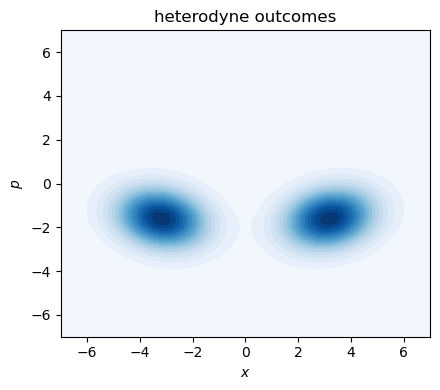

In [5]:
xs = np.linspace(-7, 7, 101)
X, P = np.meshgrid(xs, xs)
ro.Mode_Measurament(['Final', 'Heterodyne'], 0, 0.0, 1.0, np.stack([X.ravel(), P.ravel()], axis=1))
density = ro.Prob_Dis.real.reshape(X.shape)

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.contourf(xs, xs, density, 20, cmap='Blues')
ax.set_xlabel('$x$')
ax.set_ylabel('$p$')
ax.set_title('heterodyne outcomes')
plt.tight_layout()

With `'Time'` in place of `'Final'`, the same quantities are computed at every time step (`Prob_Dis_t`, `Qubit_PMS_t`), which shows how the readout improves as the pointer states form.